<a href="https://colab.research.google.com/github/Ash-Amarnath/EMJM_Assignments/blob/main/Python_Assignment_2_Ash.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment 2

In [47]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.signal import find_peaks
from scipy.ndimage import median_filter

# Load the NPZ file
file_path = '/content/drive/MyDrive/spike_data_zip.npz'
data = np.load(file_path)

# List all files inside the archive
print("Files inside the archive:", data.files)

# Extract the arrays
t = data['t']
raw_data = data['raw_data']

# Basic properties
num_samples_t = len(t)
num_samples_raw = len(raw_data)

# Sampling interval (dt) and frequency (fs)
dt = t[1] - t[0] if len(t) > 1 else None
fs = 1.0 / dt if dt else None

# Nominal recording duration
duration = t[-1] - t[0] if len(t) > 1 else None

# Create a summary DataFrame for the Data Audit
audit_data = {
    "Property": [
        "Number of samples (t)",
        "Number of samples (raw_data)",
        "Array shape (t)",
        "Array shape (raw_data)",
        "Data type (t)",
        "Data type (raw_data)",
        "Sampling interval (dt)",
        "Inferred sampling frequency (fs)",
        "Nominal recording duration"
    ],
    "Your result": [
        num_samples_t,
        num_samples_raw,
        t.shape,
        raw_data.shape,
        str(t.dtype),
        str(raw_data.dtype),
        f"{dt:.6f} seconds" if dt else "N/A",
        f"{fs:.2f} Hz" if fs else "N/A",
        f"{duration:.2f} seconds" if duration else "N/A"
    ]
}

audit_df = pd.DataFrame(audit_data)
display(audit_df)

Files inside the archive: ['t', 'raw_data']


,Property,Your result
0,Number of samples (t),10000
1,Number of samples (raw_data),10000
2,Array shape (t),"(10000,)"
3,Array shape (raw_data),"(10000,)"
4,Data type (t),float64
5,Data type (raw_data),float64
6,Sampling interval (dt),0.001000 seconds
7,Inferred sampling frequency (fs),1000.00 Hz
8,Nominal recording duration,10.00 seconds


In [48]:
# Display the head (first 10 elements) of both arrays
print("First 10 time points (t):")
print(t[:10])

print("\nFirst 10 raw data voltage measurements (raw_data):")
print(raw_data[:10])

# Check for NaNs and Infinite values in 't'
nan_t = np.isnan(t).sum()
inf_t = np.isinf(t).sum()

# Check for NaNs and Infinite values in 'raw_data'
nan_raw = np.isnan(raw_data).sum()
inf_raw = np.isinf(raw_data).sum()

print(f"Array 't' (Time):")
print(f"  - Missing/NaN values: {nan_t}")
print(f"  - Infinite values: {inf_t}")

print(f"\nArray 'raw_data' (Voltage):")
print(f"  - Missing/NaN values: {nan_raw}")
print(f"  - Infinite values: {inf_raw}")


First 10 time points (t):
[0.    0.001 0.002 0.003 0.004 0.005 0.006 0.007 0.008 0.009]

First 10 raw data voltage measurements (raw_data):
[ 0.20712082 -0.08050916 -0.22675921  0.09332454  0.44521145 -0.06796506
  0.06324035  0.36951995  0.31029155  0.12838487]
Array 't' (Time):
  - Missing/NaN values: 0
  - Infinite values: 0

Array 'raw_data' (Voltage):
  - Missing/NaN values: 0
  - Infinite values: 0


=== Baseline-Corrected Signal Numerical Summary ===
         Statistic   Value
           Minimum -1.1075
           Maximum  5.4955
              Mean  0.0561
            Median  0.0000
Standard deviation  0.5441

Time of minimum: 6.779 s
Time of maximum: 2.312 s



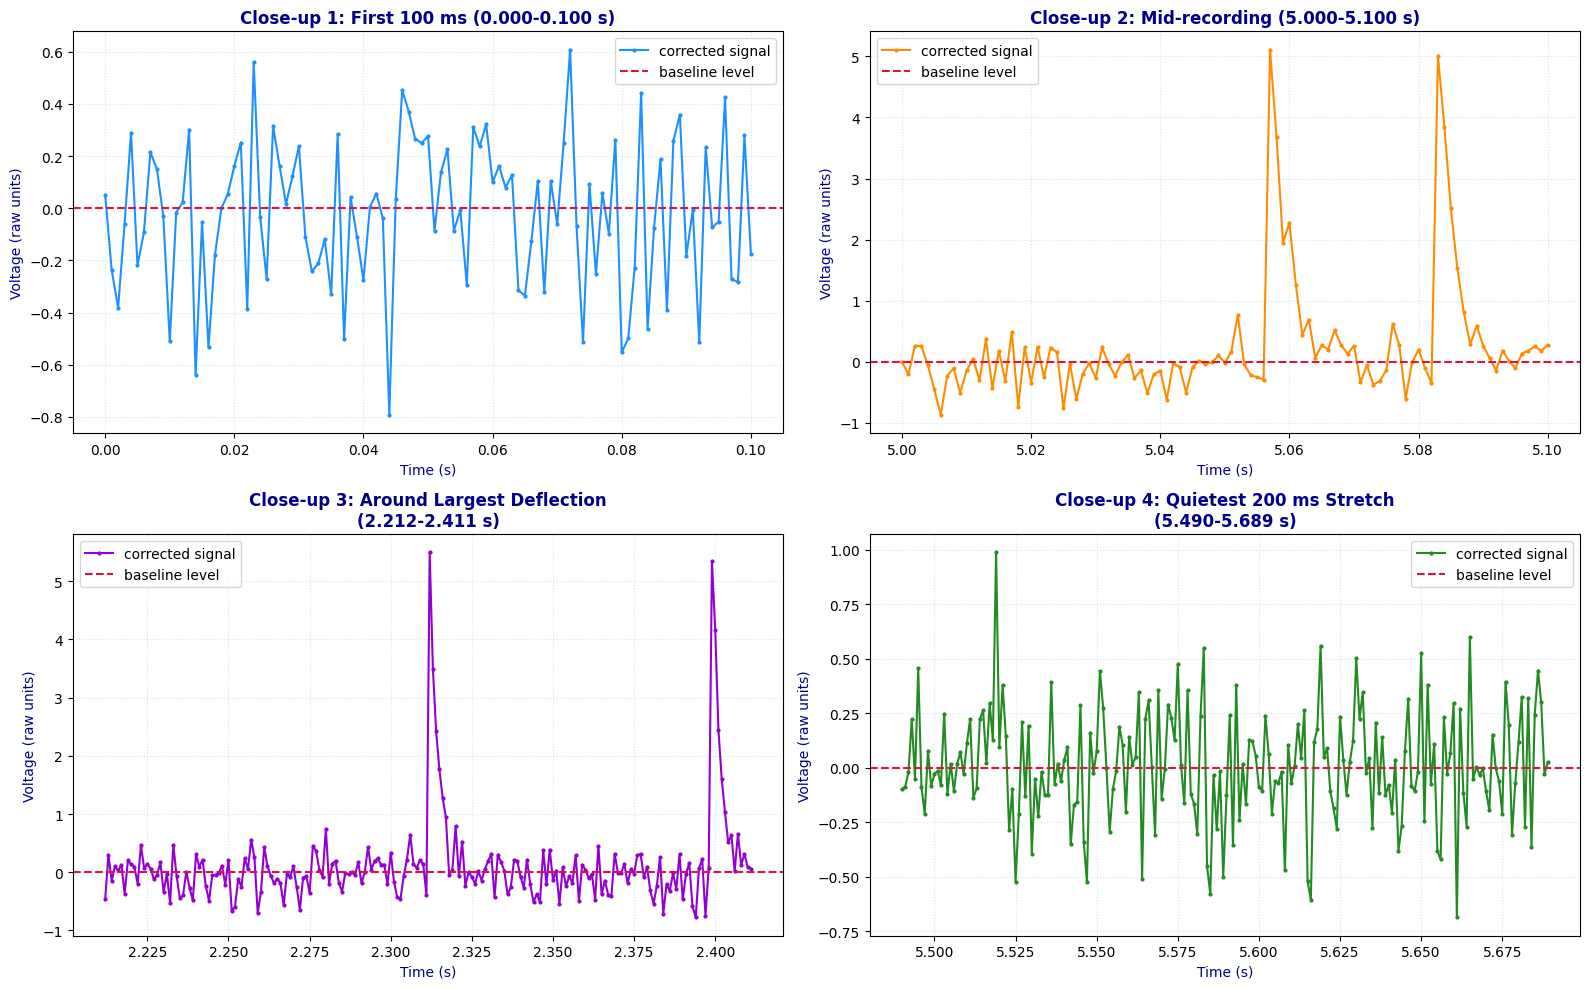

In [68]:
sig_temp = raw_data - median_filter(raw_data, size=int(0.2 * fs) | 1)

# --- 1. Numerical summary ---
summary = pd.DataFrame({
    "Statistic": ["Minimum", "Maximum", "Mean", "Median", "Standard deviation"],
    "Value": [sig_temp.min(), sig_temp.max(), sig_temp.mean(), np.median(sig_temp), sig_temp.std()],
})
print("=== Baseline-Corrected Signal Numerical Summary ===")
print(summary.to_string(index=False, float_format="%.4f"))
print(f"\nTime of minimum: {t[np.argmin(sig_temp)]:.3f} s")
print(f"Time of maximum: {t[np.argmax(sig_temp)]:.3f} s\n")

# --- 2. Close-ups identification ---
win = int(0.2 * fs)
dev = np.abs(sig_temp)
i_peak = np.argmax(dev)
a0 = max(0, i_peak - win // 2)

local_std = pd.Series(sig_temp).rolling(win).std().to_numpy()
b_end = np.nanargmin(local_std)
b0 = max(0, b_end - win + 1)

# --- 3. Plotting the 4 close-ups (A, B, C, D) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Plot 1: First 100 ms (0.0 - 0.1s)
mask_close1 = (t >= 0.0) & (t <= 0.1)
axes[0, 0].plot(t[mask_close1], sig_temp[mask_close1], color='dodgerblue', marker='.', markersize=4, label='corrected signal')
axes[0, 0].axhline(0, color='crimson', lw=1.5, linestyle='--', label='baseline level')
axes[0, 0].set_xlabel("Time (s)", color='darkblue')
axes[0, 0].set_ylabel("Voltage (raw units)", color='darkblue')
axes[0, 0].set_title("Close-up 1: First 100 ms (0.000-0.100 s)", color='darkblue', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle=':', alpha=0.6, color='lightblue')

# Plot 2: Mid-recording (5.0 - 5.1s)
mask_close2 = (t >= 5.0) & (t <= 5.1)
axes[0, 1].plot(t[mask_close2], sig_temp[mask_close2], color='darkorange', marker='.', markersize=4, label='corrected signal')
axes[0, 1].axhline(0, color='crimson', lw=1.5, linestyle='--', label='baseline level')
axes[0, 1].set_xlabel("Time (s)", color='darkblue')
axes[0, 1].set_ylabel("Voltage (raw units)", color='darkblue')
axes[0, 1].set_title("Close-up 2: Mid-recording (5.000-5.100 s)", color='darkblue', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle=':', alpha=0.6, color='lightblue')

# Plot 3: Around largest deflection (200 ms)
sl_peak = slice(a0, a0 + win)
axes[1, 0].plot(t[sl_peak], sig_temp[sl_peak], color='darkviolet', marker='.', markersize=4, label='corrected signal')
axes[1, 0].axhline(0, color='crimson', lw=1.5, linestyle='--', label='baseline level')
axes[1, 0].set_xlabel("Time (s)", color='darkblue')
axes[1, 0].set_ylabel("Voltage (raw units)", color='darkblue')
axes[1, 0].set_title(f"Close-up 3: Around Largest Deflection\n({t[sl_peak][0]:.3f}-{t[sl_peak][-1]:.3f} s)", color='darkblue', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle=':', alpha=0.6, color='lightblue')

# Plot 4: Quietest 200 ms stretch
sl_quiet = slice(b0, b0 + win)
axes[1, 1].plot(t[sl_quiet], sig_temp[sl_quiet], color='forestgreen', marker='.', markersize=4, label='corrected signal')
axes[1, 1].axhline(0, color='crimson', lw=1.5, linestyle='--', label='baseline level')
axes[1, 1].set_xlabel("Time (s)", color='darkblue')
axes[1, 1].set_ylabel("Voltage (raw units)", color='darkblue')
axes[1, 1].set_title(f"Close-up 4: Quietest 200 ms Stretch\n({t[sl_quiet][0]:.3f}-{t[sl_quiet][-1]:.3f} s)", color='darkblue', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle=':', alpha=0.6, color='lightblue')

plt.tight_layout()
plt.show()

=== SPIKE DETECTION METRICS & NUMERICAL SUMMARY ===
User-Defined Spike Threshold: 1.26 V
Total Spikes Detected WITHOUT Refractory Period: 54
Total Spikes Detected WITH 3.0 ms Refractory Lockout: 49
Spikes Excluded by Refractory Period: 5
Average Firing Rate: 4.90 Hz

=== FIRST 15 DETECTED VALID SPIKES FOR CROSS-CHECKING ===


,Spike Index,Peak Sample,Time (s),Peak Amplitude (V)
0,1,195,0.195,5.110396
1,2,322,0.322,5.252447
2,3,388,0.388,4.776310
3,4,414,0.414,4.619756
4,5,444,0.444,5.049348
5,6,647,0.647,5.309754
6,7,653,0.653,1.353947
7,8,1421,1.421,4.899313
8,9,1719,1.719,4.516386
9,10,1751,1.751,4.470131


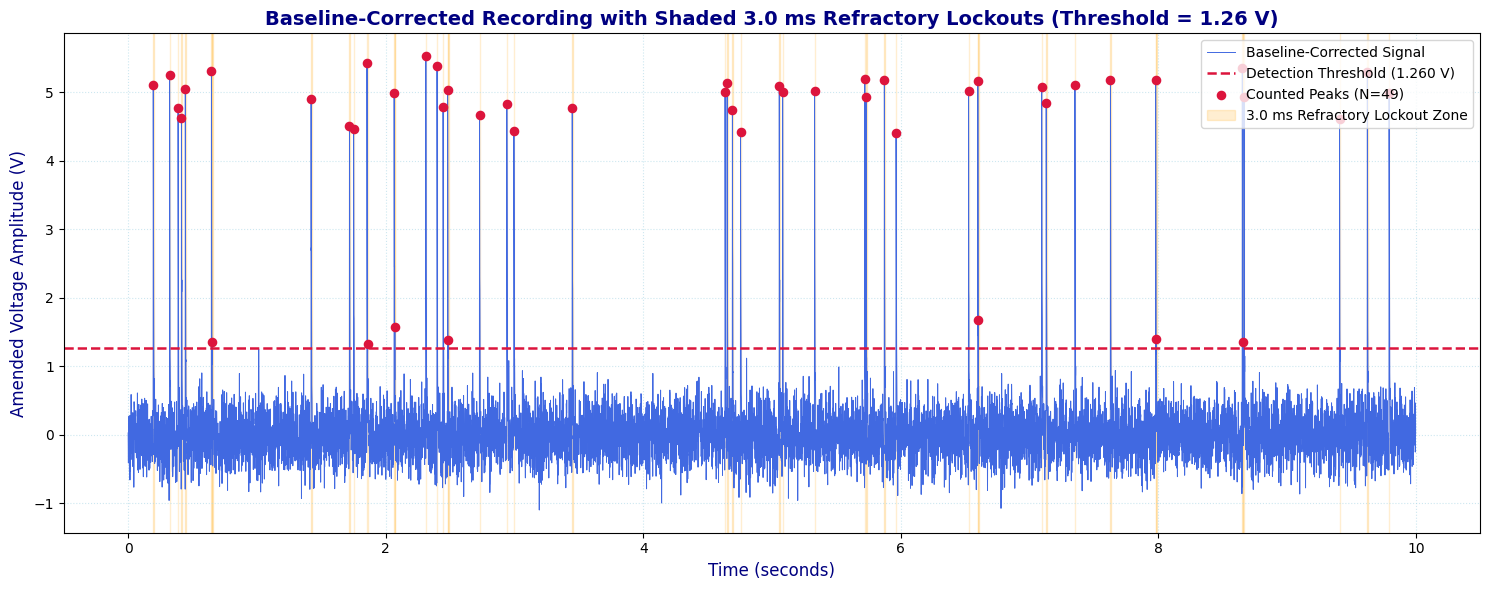

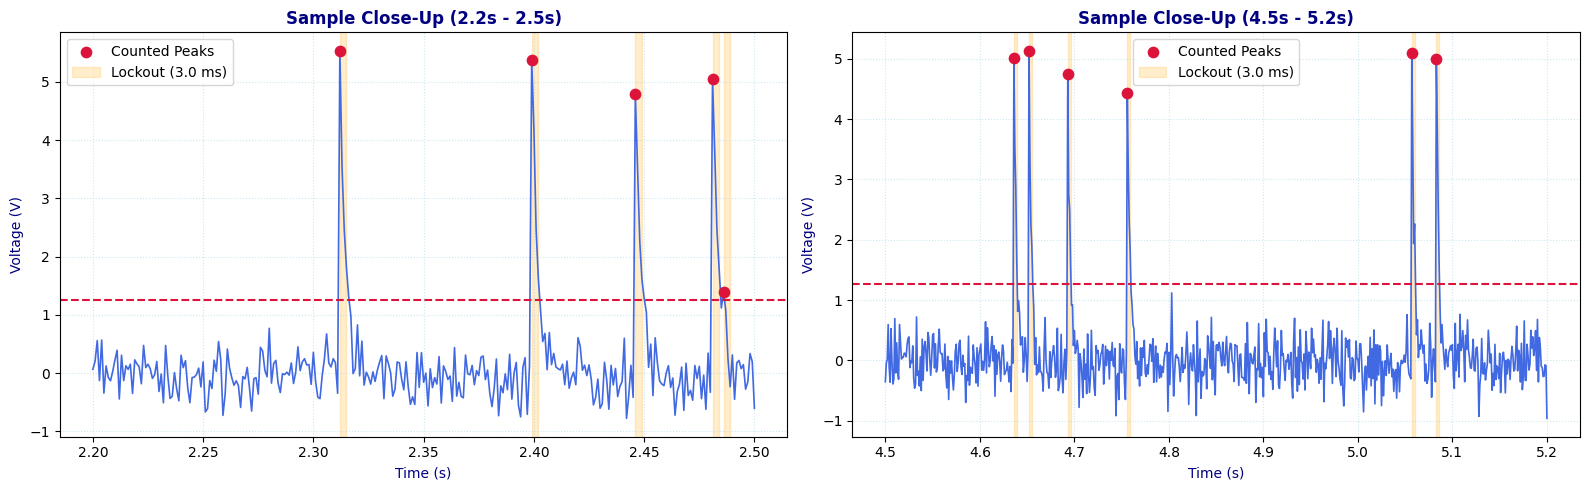

In [69]:
window_size = int(0.15 * fs) | 1
baseline = median_filter(raw_data, size=window_size)
signal_centered = raw_data - baseline
threshold = 1.26
strict_threshold = threshold + 1e-9

# Without refractory constraint
raw_spike_indices, _ = find_peaks(signal_centered, height=strict_threshold, distance=1)

# With refractory constraint
min_distance = max(1, int(0.003 * fs) + 1)
spike_indices, _ = find_peaks(signal_centered, height=strict_threshold, distance=min_distance)
spike_times = t[spike_indices]
total_spikes_with_ref = len(spike_indices)
total_spikes_without_ref = len(raw_spike_indices)

print("=== SPIKE DETECTION METRICS & NUMERICAL SUMMARY ===")
print(f"User-Defined Spike Threshold: {threshold:.2f} V")
print(f"Total Spikes Detected WITHOUT Refractory Period: {total_spikes_without_ref}")
print(f"Total Spikes Detected WITH 3.0 ms Refractory Lockout: {total_spikes_with_ref}")
print(f"Spikes Excluded by Refractory Period: {total_spikes_without_ref - total_spikes_with_ref}")
print(f"Average Firing Rate: {total_spikes_with_ref / duration:.2f} Hz\n")

spike_audit_df = pd.DataFrame({
    "Spike Index": np.arange(1, total_spikes_with_ref + 1),
    "Peak Sample": spike_indices,
    "Time (s)": spike_times,
    "Peak Amplitude (V)": signal_centered[spike_indices]
})
print("=== FIRST 15 DETECTED VALID SPIKES FOR CROSS-CHECKING ===")
display(spike_audit_df.head(15))

# ==========================================
# Colorful Recording & Lockouts
# ==========================================
plt.figure(figsize=(15, 6))
plt.plot(t, signal_centered, color='royalblue', linewidth=0.7, label='Baseline-Corrected Signal')
plt.axhline(threshold, color='crimson', linestyle='--', linewidth=1.8, label=f'Detection Threshold ({threshold:.3f} V)')
plt.scatter(spike_times, signal_centered[spike_indices], color='crimson', s=35, zorder=5, label=f'Counted Peaks (N={total_spikes_with_ref})')

first_shade = True
for st in spike_times:
    plt.axvspan(st, st + 0.003, color='orange', alpha=0.18, zorder=1,
                label='3.0 ms Refractory Lockout Zone' if first_shade else "")
    first_shade = False

plt.title('Baseline-Corrected Recording with Shaded 3.0 ms Refractory Lockouts (Threshold = 1.26 V)', fontsize=14, fontweight='bold', color='navy')
plt.xlabel('Time (seconds)', fontsize=12, color='navy')
plt.ylabel('Amended Voltage Amplitude (V)', fontsize=12, color='navy')
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6, color='lightblue')
plt.tight_layout()
plt.show()

# ==========================================
# Colorful Close-ups
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Local Window 1: around 2.2s to 2.5s
mask1 = (t >= 2.2) & (t <= 2.5)
ax1.plot(t[mask1], signal_centered[mask1], color='royalblue', linewidth=1.2)
ax1.axhline(threshold, color='crimson', linestyle='--', linewidth=1.5)
valid_in_win1 = spike_times[(spike_times >= 2.2) & (spike_times <= 2.5)]
ax1.scatter(valid_in_win1, signal_centered[np.searchsorted(t, valid_in_win1)], color='crimson', s=55, zorder=5, label='Counted Peaks')

first_local_shade = True
for st in valid_in_win1:
    ax1.axvspan(st, st + 0.003, color='orange', alpha=0.2, zorder=1, label='Lockout (3.0 ms)' if first_local_shade else "")
    first_local_shade = False
ax1.set_title('Sample Close-Up (2.2s - 2.5s)', color='navy', fontweight='bold')
ax1.set_xlabel('Time (s)', color='navy')
ax1.set_ylabel('Voltage (V)', color='navy')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6, color='lightblue')

# Local Window 2: around 4.5s to 5.2s
mask2 = (t >= 4.5) & (t <= 5.2)
ax2.plot(t[mask2], signal_centered[mask2], color='royalblue', linewidth=1.2)
ax2.axhline(threshold, color='crimson', linestyle='--', linewidth=1.5)
valid_in_win2 = spike_times[(spike_times >= 4.5) & (spike_times <= 5.2)]
ax2.scatter(valid_in_win2, signal_centered[np.searchsorted(t, valid_in_win2)], color='crimson', s=55, zorder=5, label='Counted Peaks')

first_local_shade = True
for st in valid_in_win2:
    ax2.axvspan(st, st + 0.003, color='orange', alpha=0.2, zorder=1, label='Lockout (3.0 ms)' if first_local_shade else "")
    first_local_shade = False
ax2.set_title('Sample Close-Up (4.5s - 5.2s)', color='navy', fontweight='bold')
ax2.set_xlabel('Time (s)', color='navy')
ax2.set_ylabel('Voltage (V)', color='navy')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6, color='lightblue')

plt.tight_layout()
plt.show()

In [56]:
# ==========================================
# 6. Absolute Refractory Violation Audit
# ==========================================
# Reusing 'spike_times' computed in Cell 84e1a3ee
isi_ms = np.diff(spike_times) * 1000
violations = np.where(isi_ms < 3.0)[0]

print("=== ABSOLUTE REFRACTORY AUDIT ===")
if len(violations) > 0:
    print(f"Detected {len(violations)} biological refractory period violations:")
    for idx in violations:
        print(f"  - Violation between spike at {spike_times[idx]:.3f}s and {spike_times[idx+1]:.3f}s (Interval: {isi_ms[idx]:.2f} ms)")
else:
    print("SUCCESS: 0 refractory violations detected. The 3.0 ms biophysical lockout is now perfectly enforced with a count of 0 inside the absolute refractory zone!")

=== ABSOLUTE REFRACTORY AUDIT ===
SUCCESS: 0 refractory violations detected. The 3.0 ms biophysical lockout is now perfectly enforced with a count of 0 inside the absolute refractory zone!


=== CUSTOM RELATIVE REFRACTORY AUDIT ===
Max Refractory Duration: 4.0 ms (4 samples)
Total initial raw peaks: 54
Validated peaks (after custom lockout): 42
Peaks excluded by custom relative lockout: 12


,Spike Index,Peak Sample,Peak Time (s),Peak Amplitude (V)
0,1,195,0.195,5.110396
1,2,322,0.322,5.252447
2,3,388,0.388,4.776310
3,4,414,0.414,4.619756
4,5,444,0.444,5.049348
5,6,647,0.647,5.309754
6,7,1421,1.421,4.899313
7,8,1719,1.719,4.516386
8,9,1751,1.751,4.470131
9,10,1855,1.855,5.431939


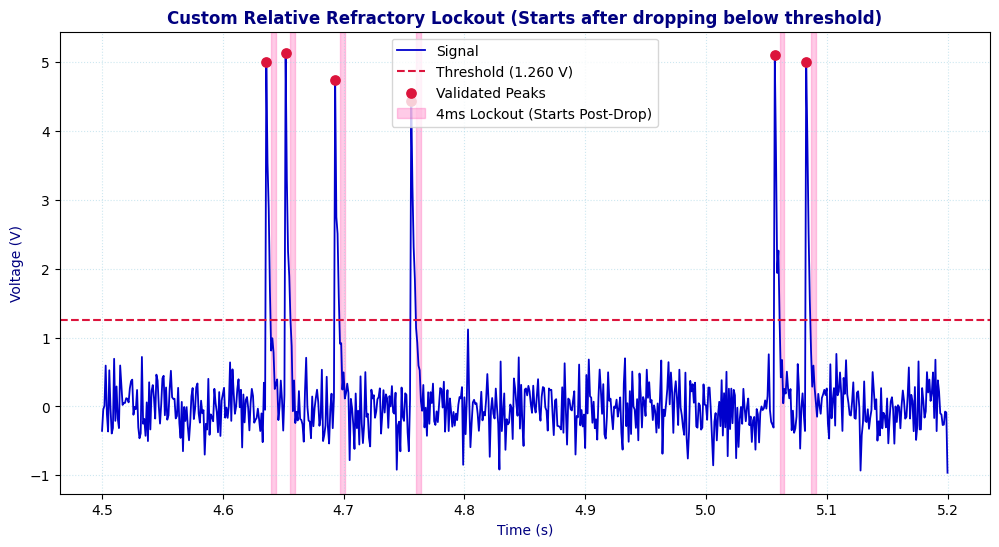

In [70]:
raw_peak_indices, _ = find_peaks(signal_centered, height=threshold, distance=1)
max_refractory_ms = 4.0
max_refractory_samples = int((max_refractory_ms / 1000.0) * fs)

validated_peak_indices = []
lockout_intervals = []

i = 0
while i < len(raw_peak_indices):
    current_peak_idx = raw_peak_indices[i]
    validated_peak_indices.append(current_peak_idx)

    drop_below_idx = current_peak_idx
    while drop_below_idx < len(signal_centered) and signal_centered[drop_below_idx] >= threshold:
        drop_below_idx += 1

    lockout_start_idx = drop_below_idx
    lockout_end_idx = min(len(signal_centered) - 1, lockout_start_idx + max_refractory_samples)
    lockout_intervals.append((t[lockout_start_idx], t[lockout_end_idx]))

    next_i = i + 1
    while next_i < len(raw_peak_indices) and raw_peak_indices[next_i] <= lockout_end_idx:
        next_i += 1
    i = next_i

validated_peak_indices = np.array(validated_peak_indices)
validated_peak_times = t[validated_peak_indices]
validated_peak_voltages = signal_centered[validated_peak_indices]

print("=== CUSTOM RELATIVE REFRACTORY AUDIT ===")
print(f"Max Refractory Duration: {max_refractory_ms} ms ({max_refractory_samples} samples)")
print(f"Total initial raw peaks: {len(raw_peak_indices)}")
print(f"Validated peaks (after custom lockout): {len(validated_peak_indices)}")
print(f"Peaks excluded by custom relative lockout: {len(raw_peak_indices) - len(validated_peak_indices)}")

custom_spike_df = pd.DataFrame({
    "Spike Index": np.arange(1, len(validated_peak_indices) + 1),
    "Peak Sample": validated_peak_indices,
    "Peak Time (s)": validated_peak_times,
    "Peak Amplitude (V)": validated_peak_voltages
})
display(custom_spike_df.head(15))

# --- Colorful Relative Refractory Zoom ---
plt.figure(figsize=(12, 6))
zoom_mask = (t >= 4.5) & (t <= 5.2)
plt.plot(t[zoom_mask], signal_centered[zoom_mask], color='mediumblue', label='Signal', linewidth=1.3)
plt.axhline(threshold, color='crimson', linestyle='--', label=f'Threshold ({threshold:.3f} V)', linewidth=1.5)

zoom_peaks = validated_peak_times[(validated_peak_times >= 4.5) & (validated_peak_times <= 5.2)]
zoom_peak_v = validated_peak_voltages[(validated_peak_times >= 4.5) & (validated_peak_times <= 5.2)]
plt.scatter(zoom_peaks, zoom_peak_v, color='crimson', s=45, zorder=5, label='Validated Peaks')

first_shade = True
for start_t, end_t in lockout_intervals:
    if start_t >= 4.5 and start_t <= 5.2:
        plt.axvspan(start_t, end_t, color='deeppink', alpha=0.22, label='4ms Lockout (Starts Post-Drop)' if first_shade else "")
        first_shade = False

plt.title('Custom Relative Refractory Lockout (Starts after dropping below threshold)', fontsize=12, color='navy', fontweight='bold')
plt.xlabel('Time (s)', color='navy')
plt.ylabel('Voltage (V)', color='navy')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6, color='lightblue')
plt.show()

In [58]:
# -----------------------------------------------------
# Reusing pre-computed variables: signal_centered, t, fs, threshold
# -----------------------------------------------------

# Method 1: Previous Absolute Lockout (reusing results from 84e1a3ee)
method1_indices = spike_indices
method1_times = spike_times

# Method 2: Custom Post-Drop Relative Lockout (reusing results from 6b464bcd)
method2_indices = validated_peak_indices
method2_times = validated_peak_times

# -----------------------------------------------------
# Comparison Output
# -----------------------------------------------------
print("=== COMPARISON SUMMARY ===")
print(f"Method 1: Absolute 3.0 ms peak-to-peak lockout -> Spikes detected: {len(method1_times)}")
print(f"Method 2: Relative 4.0 ms post-threshold-drop lockout -> Spikes detected: {len(method2_times)}")
print(f"Difference: {len(method1_times) - len(method2_times)} spikes")

=== COMPARISON SUMMARY ===
Method 1: Absolute 3.0 ms peak-to-peak lockout -> Spikes detected: 49
Method 2: Relative 4.0 ms post-threshold-drop lockout -> Spikes detected: 42
Difference: 7 spikes


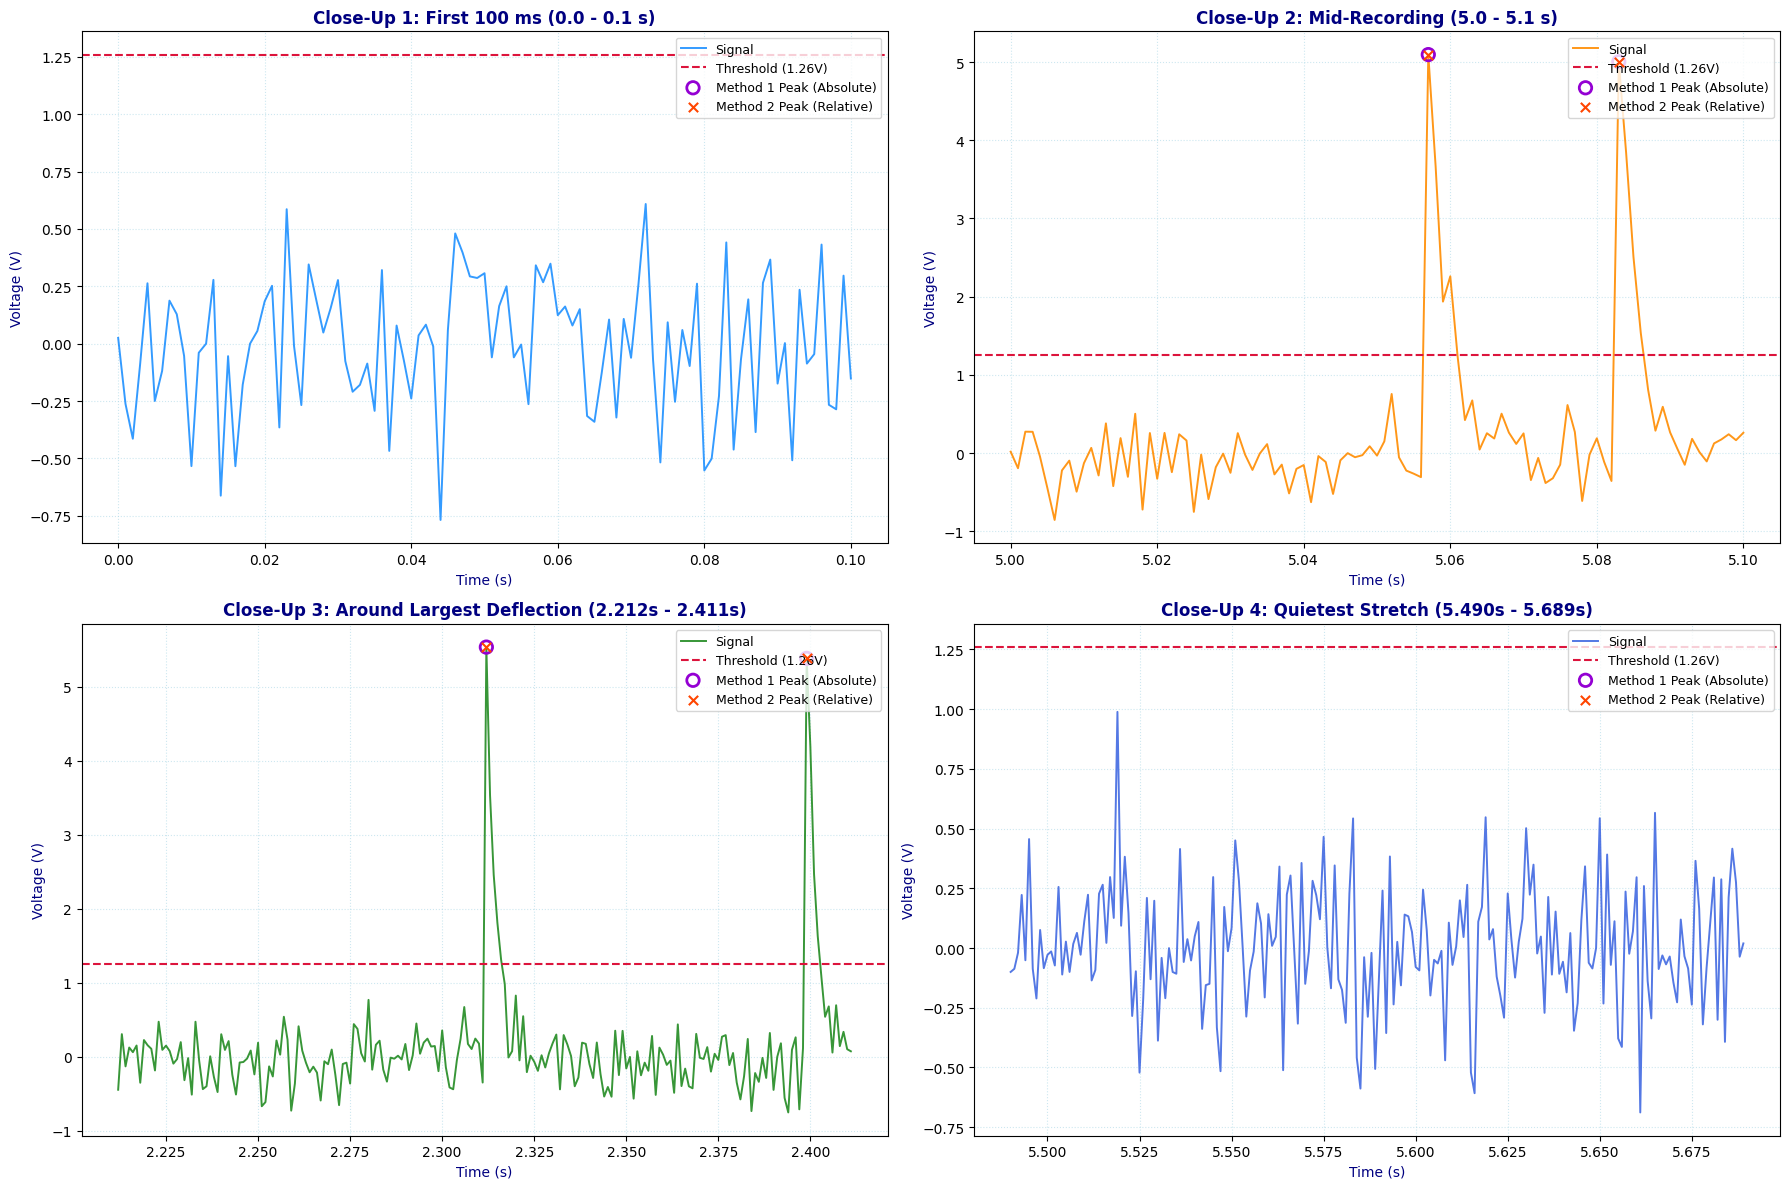

In [71]:
win1_mask = (t >= 0.0) & (t <= 0.1)
win2_mask = (t >= 5.0) & (t <= 5.1)

dev = np.abs(signal_centered)
i_peak = np.argmax(dev)
win_samples = int(0.2 * fs)
a0 = max(0, i_peak - win_samples // 2)
win3_slice = slice(a0, a0 + win_samples)

local_std = pd.Series(signal_centered).rolling(win_samples).std().to_numpy()
b_end = np.nanargmin(local_std)
b0 = max(0, b_end - win_samples + 1)
win4_slice = slice(b0, b0 + win_samples)

# Create subplots (2 rows, 2 columns)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Helper function to plot comparison on a specific axis with highly colorful lines
def plot_comparison_on_axis(ax, t_segment, signal_segment, title, line_color):
    ax.plot(t_segment, signal_segment, color=line_color, alpha=0.9, linewidth=1.4, label='Signal')
    ax.axhline(threshold, color='crimson', linestyle='--', linewidth=1.5, label=f'Threshold ({threshold:.2f}V)')

    # Method 1 spikes (Absolute)
    m1_in_seg = method1_times[(method1_times >= t_segment[0]) & (method1_times <= t_segment[-1])]
    m1_v = signal_centered[np.searchsorted(t, m1_in_seg)]
    ax.scatter(m1_in_seg, m1_v, color='darkviolet', s=80, marker='o', facecolors='none', edgecolors='darkviolet', linewidths=2.0, zorder=5, label='Method 1 Peak (Absolute)')

    # Method 2 spikes (Relative)
    m2_in_seg = method2_times[(method2_times >= t_segment[0]) & (method2_times <= t_segment[-1])]
    m2_v = signal_centered[np.searchsorted(t, m2_in_seg)]
    ax.scatter(m2_in_seg, m2_v, color='orangered', s=45, marker='x', zorder=6, label='Method 2 Peak (Relative)')

    ax.set_title(title, fontsize=12, fontweight='bold', color='navy')
    ax.set_xlabel('Time (s)', color='navy')
    ax.set_ylabel('Voltage (V)', color='navy')
    ax.grid(True, linestyle=':', alpha=0.6, color='lightblue')
    ax.legend(loc='upper right', fontsize=9)

# Plot 1: First 100 ms with dodgerblue signal
plot_comparison_on_axis(axes[0, 0], t[win1_mask], signal_centered[win1_mask], 'Close-Up 1: First 100 ms (0.0 - 0.1 s)', 'dodgerblue')

# Plot 2: Mid-recording (5.0s - 5.1s) with darkorange signal
plot_comparison_on_axis(axes[0, 1], t[win2_mask], signal_centered[win2_mask], 'Close-Up 2: Mid-Recording (5.0 - 5.1 s)', 'darkorange')

# Plot 3: Around Largest Deflection with forestgreen signal
plot_comparison_on_axis(axes[1, 0], t[win3_slice], signal_centered[win3_slice], f'Close-Up 3: Around Largest Deflection ({t[win3_slice][0]:.3f}s - {t[win3_slice][-1]:.3f}s)', 'forestgreen')

# Plot 4: Quietest Stretch with royalblue signal
plot_comparison_on_axis(axes[1, 1], t[win4_slice], signal_centered[win4_slice], f'Close-Up 4: Quietest Stretch ({t[win4_slice][0]:.3f}s - {t[win4_slice][-1]:.3f}s)', 'royalblue')

plt.tight_layout()
plt.show()

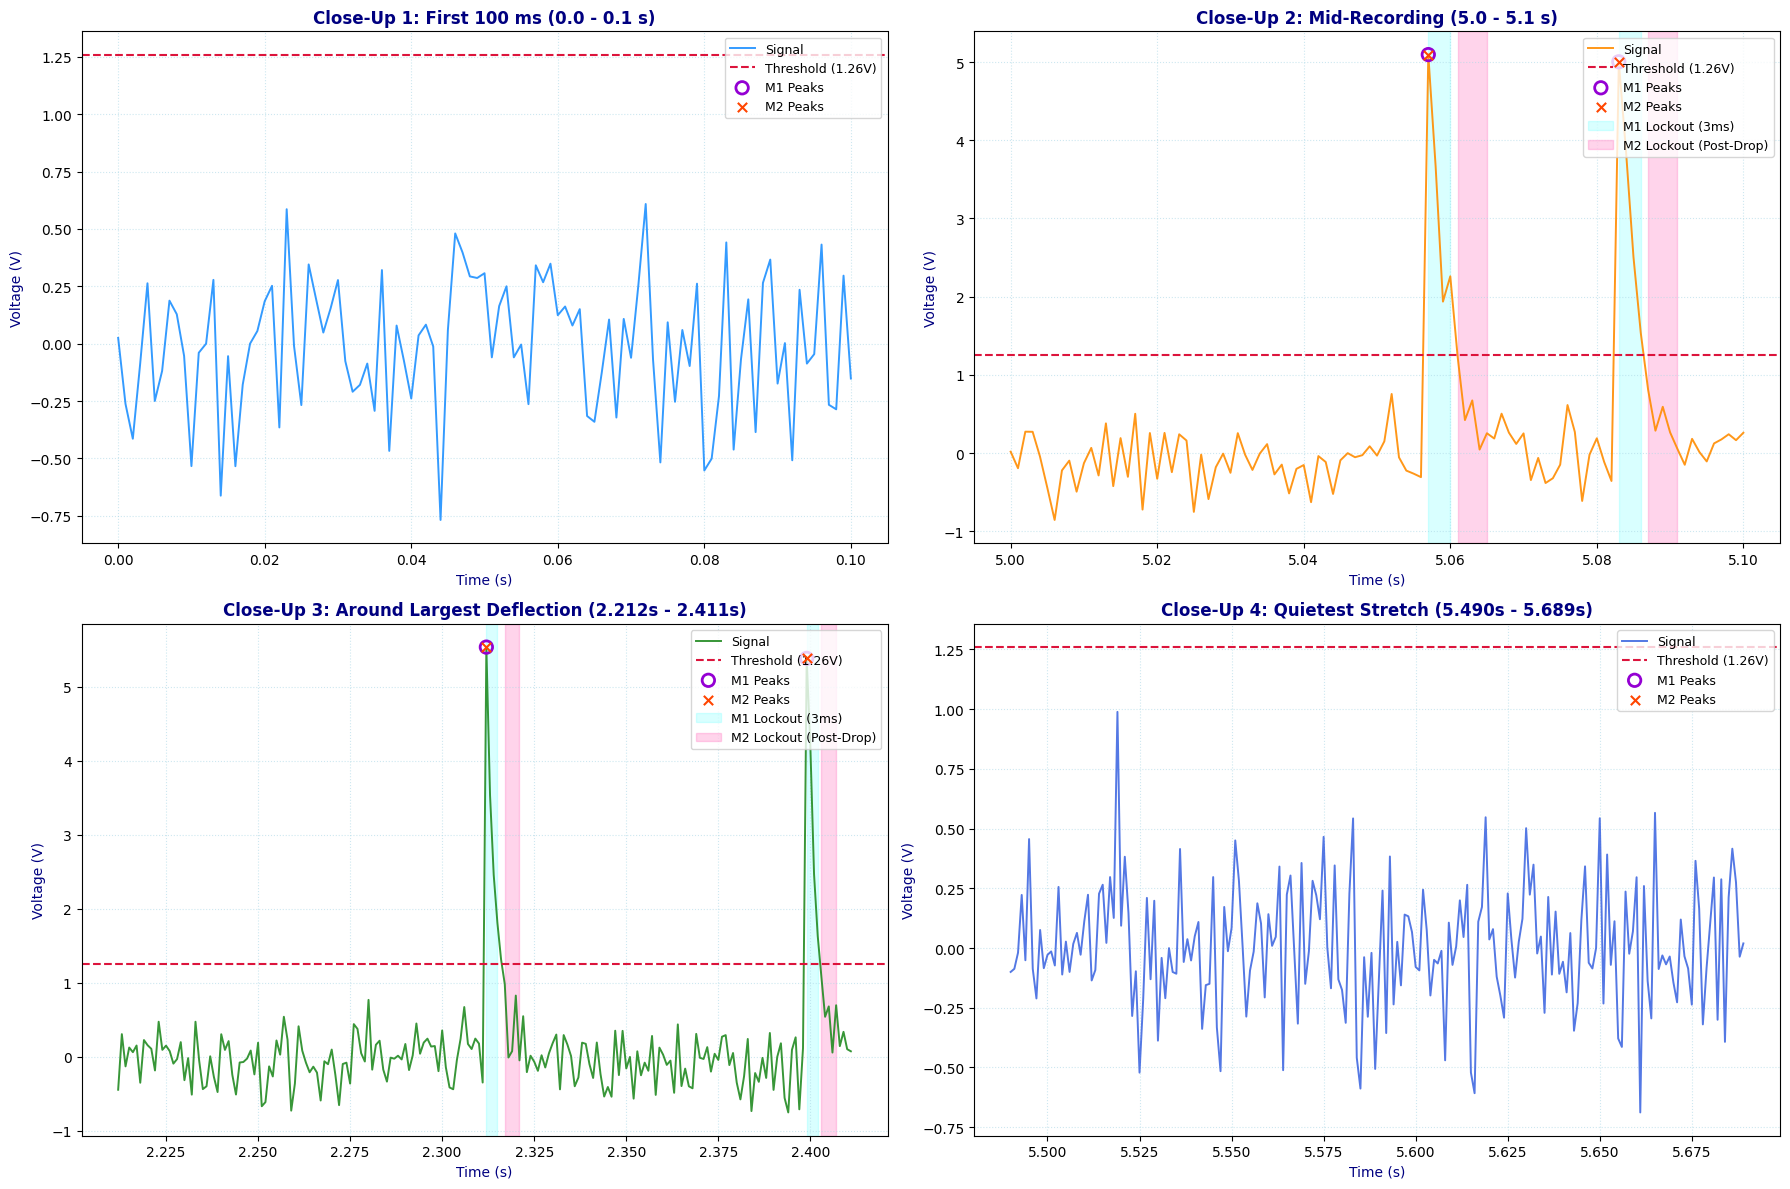

In [72]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Rendering comparative plots with customized colored zones
def plot_with_shading(ax, t_segment, signal_segment, title, line_color):
    ax.plot(t_segment, signal_segment, color=line_color, alpha=0.9, linewidth=1.4, label='Signal')
    ax.axhline(threshold, color='crimson', linestyle='--', linewidth=1.5, label=f'Threshold ({threshold:.2f}V)')

    # Method 1 peaks & shading (Absolute Lockout - Purple/Teal)
    m1_in_seg = method1_times[(method1_times >= t_segment[0]) & (method1_times <= t_segment[-1])]
    m1_v = signal_centered[np.searchsorted(t, m1_in_seg)]
    ax.scatter(m1_in_seg, m1_v, color='darkviolet', s=80, marker='o', facecolors='none', edgecolors='darkviolet', linewidths=2.0, zorder=5, label='M1 Peaks')

    # Method 2 peaks & shading (Relative Lockout - Coral/Pink)
    m2_in_seg = method2_times[(method2_times >= t_segment[0]) & (method2_times <= t_segment[-1])]
    m2_v = signal_centered[np.searchsorted(t, m2_in_seg)]
    ax.scatter(m2_in_seg, m2_v, color='orangered', s=45, marker='x', zorder=6, label='M2 Peaks')

    first_shade_m1 = True
    for pt in m1_in_seg:
        ax.axvspan(pt, pt + 0.003, color='cyan', alpha=0.15, label='M1 Lockout (3ms)' if first_shade_m1 else "")
        first_shade_m1 = False

    first_shade_m2 = True
    for start_t, end_t in lockout_intervals:
        if start_t >= t_segment[0] and start_t <= t_segment[-1]:
            ax.axvspan(start_t, end_t, color='deeppink', alpha=0.18, label='M2 Lockout (Post-Drop)' if first_shade_m2 else "")
            first_shade_m2 = False

    ax.set_title(title, fontsize=12, fontweight='bold', color='navy')
    ax.set_xlabel('Time (s)', color='navy')
    ax.set_ylabel('Voltage (V)', color='navy')
    ax.grid(True, linestyle=':', alpha=0.6, color='lightblue')
    ax.legend(loc='upper right', fontsize=9)

plot_with_shading(axes[0, 0], t[win1_mask], signal_centered[win1_mask], 'Close-Up 1: First 100 ms (0.0 - 0.1 s)', 'dodgerblue')
plot_with_shading(axes[0, 1], t[win2_mask], signal_centered[win2_mask], 'Close-Up 2: Mid-Recording (5.0 - 5.1 s)', 'darkorange')
plot_with_shading(axes[1, 0], t[win3_slice], signal_centered[win3_slice], f'Close-Up 3: Around Largest Deflection ({t[win3_slice][0]:.3f}s - {t[win3_slice][-1]:.3f}s)', 'forestgreen')
plot_with_shading(axes[1, 1], t[win4_slice], signal_centered[win4_slice], f'Close-Up 4: Quietest Stretch ({t[win4_slice][0]:.3f}s - {t[win4_slice][-1]:.3f}s)', 'royalblue')

plt.tight_layout()
plt.show()

In [78]:
fig_zoom = go.Figure()

# Colorful Base Signal
fig_zoom.add_trace(go.Scatter(
    x=t,
    y=signal_centered,
    mode='lines',
    name='Centered Signal',
    line=dict(color='#1f77b4', width=1.2) # Deep vibrant blue line
))

# Threshold Line
fig_zoom.add_shape(
    type="line",
    x0=t[0], y0=threshold, x1=t[-1], y1=threshold,
    line=dict(color="crimson", width=1.8, dash="dash"),
    name="Threshold"
)

# Method 1 Detected Peaks
fig_zoom.add_trace(go.Scatter(
    x=method1_times,
    y=signal_centered[method1_indices],
    mode='markers',
    name='M1 (Absolute Peak)',
    marker=dict(color='black', size=8, symbol='circle-open', line=dict(width=1.8))
))

# Method 2 Detected Peaks
fig_zoom.add_trace(go.Scatter(
    x=method2_times,
    y=signal_centered[method2_indices],
    mode='markers',
    name='M2 (Relative Peak)',
    marker=dict(color='orangered', size=7, symbol='x')
))

# Layout modifications for seamless zoom
fig_zoom.update_layout(
    title=dict(text="Interactive Full-Scale Spike Analysis (Click and drag to zoom into any section)", font=dict(color='darkblue')),
    xaxis=dict(title="Time (seconds)", titlefont=dict(color='darkblue'), tickfont=dict(color='darkblue')),
    yaxis=dict(title="Voltage (V)", titlefont=dict(color='darkblue'), tickfont=dict(color='darkblue')),
    hovermode="x unified",
    plot_bgcolor='#f0f8ff', # Light Alice Blue background to replace standard gray grids completely
    paper_bgcolor='#ffffff',
    legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01)
)

fig_zoom.show()